In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#helix and loop for figure from https://biodraws.com/alpha-helix/
#arrows are form https://upload.wikimedia.org/wikipedia/commons/f/fa/Equilibrium_arrow.svg
#page = https://commons.wikimedia.org/wiki/File:Equilibrium_arrow.svg

In [3]:
# A helix propensity scale based on experimental studies of peptides and proteins.
# C N Pace 1, J M Scholtz 1 
# Biophys J. 1998 Jul;75(1):422–427. doi: 10.1016/s0006-3495(98)77529-0 
# Ala = 0, Leu = 0.21, Arg = 0.21, Met = 0.24, Lys = 0.26, Gln = 0.39, Glu = 0.40, Ile = 0.41, Trp = 0.49, Ser = 0.50, 
# Tyr = 0.53, Phe = 0.54, Val = 0.61, His = 0.61, Asn = 0.65, Thr = 0.66, Cys = 0.68, Asp = 0.69, and Gly = 1.

helical_propensities = {
    "Ala": 0.00,
    "Leu": 0.21,
    "Arg": 0.21,
    "Met": 0.24,
    "Lys": 0.26,
    "Gln": 0.39,
    "Glu": 0.40,
    "Ile": 0.41,
    "Trp": 0.49,
    "Ser": 0.50,
    "Tyr": 0.53,
    "Phe": 0.54,
    "Val": 0.61,
    "His": 0.61,
    "Asn": 0.65,
    "Thr": 0.66,
    "Cys": 0.68,
    "Asp": 0.69,
    "Gly": 1.00,
    }


In [4]:
#transfer free energy from:
#Hessa, T., Kim, H., Bihlmaier, K. et al. Recognition of transmembrane helices by the endoplasmic reticulum translocon. Nature 433, 377–381 (2005). https://doi.org/10.1038/nature03216

hessa_von_heijne_scale = {
    "Leu": -0.55,
    "Ile": -0.60,
    "Phe": -0.32,
    "Val": -0.31,
    "Cys": -0.13,
    "Met": -0.10,
    "Ala": 0.11,
    "Trp": 0.30,
    "Thr": 0.52,
    "Tyr": 0.68,
    "Gly": 0.74,
    "Ser": 0.84,
    "Asn": 2.05,
    "His": 2.06,
    "Pro": 2.23,
    "Gln": 2.36,
    "Lys": 2.71,
    "Arg": 2.58,
    "Glu": 2.68,
    "Asp": 3.49
    }


In [18]:
# Mitochondrial inner membrane ΔG_app^X scale (kcal/mol)
# Botelho et al. (2011) EMBO J 30:1003-1011, Figure 3A
delta_G_mito = {
    'Leu': -0.20,  # from the text (Leu/Ala fit), not a bar measurement
    'Ile': -0.02,
    'Met':  0.04,
    'Ala':  0.09,  # from the text (Leu/Ala fit), not a bar measurement
    'Val':  0.16,
    'Phe':  0.17,
    'Cys':  0.18,
    'Thr':  0.25,
    'Gly':  0.43,
    'Ser':  0.56,
    'Trp':  1.12,
    'Asn':  1.41,
    'Lys':  1.56,
    'Pro':  1.65,
    'His':  1.77,
    'Tyr':  1.83,
    'Asp':  2.09,
    'Gln':  2.23,
    'Glu':  2.55,
    'Arg':  3.01,
}


#plt.bar([x for x in range(len(delta_G_mito))], np.sort(np.array([i for i in delta_G_mito.values()])))

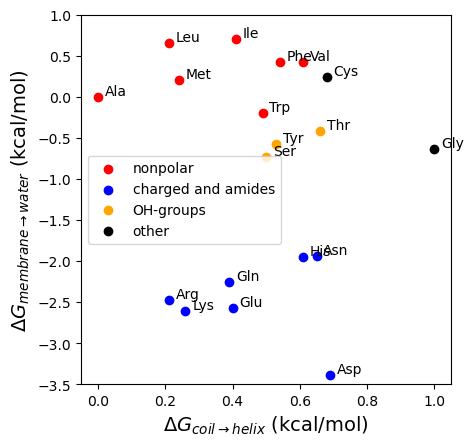

In [19]:
three_letter_aas_nopro = [
    "Ala", "Arg", "Asn", "Asp", 
    "Gln", "Glu", "His", "Ile",
    "Leu", "Lys", "Met", "Phe", 
    "Ser", "Thr", "Trp", "Tyr", "Val", 
    "Cys", "Gly"
]

three_letter_colors_nopro = [
    "red", "blue", "blue", "blue", 
    "blue", "blue", "blue", "red",
    "red", "blue", "red", "red", 
    "orange", "orange", "red", "orange", "red", 
    "black", "black"
]

fig, ax = plt.subplots()

for aa, color in zip(three_letter_aas_nopro, three_letter_colors_nopro):

    if aa == "Ala":
        label = "nonpolar"
    elif aa == "Ser": 
        label = "OH-groups"
    elif aa == "Gln":
        label = "charged and amides"
    elif aa == "Cys":
        label = "other"
    else:
        label = "_nolabel_"

    plt.scatter(helical_propensities[aa], -(hessa_von_heijne_scale[aa]-hessa_von_heijne_scale["Ala"]), c = color, label = label)
    plt.text(helical_propensities[aa]+0.02, -(hessa_von_heijne_scale[aa]-hessa_von_heijne_scale["Ala"])+0.02, aa)

plt.legend(loc = 'center left')
#plt.legend(["nonpolar", "OH-groups", "charged and amides", "other"])

plt.xlabel(r"$\Delta G_{coil \rightarrow helix}$ (kcal/mol)", fontsize=14)
plt.ylabel(r"$\Delta G_{membrane \rightarrow water}$ (kcal/mol)", fontsize=14)

plt.xlim(-0.05,1.05)
plt.ylim(-3.5,1)

ax.set_box_aspect(1)

version = 1
plt.savefig(f"figures/pace_hessa_helicity_hydrophobicity_v{version}", bbox_inches='tight', dpi=600)
plt.savefig(f"figures/pace_hessa_helicity_hydrophobicity_v{version}.svg", bbox_inches='tight', format="svg")



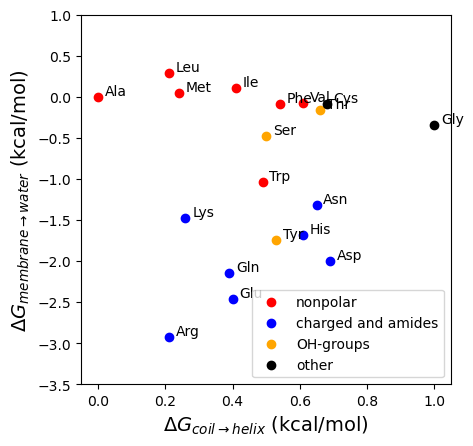

In [21]:
fig, ax = plt.subplots()

for aa, color in zip(three_letter_aas_nopro, three_letter_colors_nopro):

    if aa == "Ala":
        label = "nonpolar"
    elif aa == "Ser": 
        label = "OH-groups"
    elif aa == "Gln":
        label = "charged and amides"
    elif aa == "Cys":
        label = "other"
    else:
        label = "_nolabel_"

    plt.scatter(helical_propensities[aa], -(delta_G_mito[aa]-delta_G_mito["Ala"]), c = color, label = label)
    plt.text(helical_propensities[aa]+0.02, -(delta_G_mito[aa]-delta_G_mito["Ala"])+0.02, aa)

plt.legend()
#plt.legend(["nonpolar", "OH-groups", "charged and amides", "other"])

plt.xlabel(r"$\Delta G_{coil \rightarrow helix}$ (kcal/mol)", fontsize=14)
plt.ylabel(r"$\Delta G_{membrane \rightarrow water}$ (kcal/mol)", fontsize=14)

plt.xlim(-0.05,1.05)
plt.ylim(-3.5,1)

ax.set_box_aspect(1)

version = 1
plt.savefig(f"figures/pace_botelho_helicity_hydrophobicity_v{version}", bbox_inches='tight', dpi=600)
plt.savefig(f"figures/pace_botelho_helicity_hydrophobicity_v{version}.svg", bbox_inches='tight', format="svg")